# Trabajo Práctico 3: Clasificación de imágenes satelitales

In [67]:
import csv
import json
import random
import time
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from IPython.display import display, Markdown
from torchvision import models


In [68]:
#semilla
SEED = 22
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [69]:
#Dispositivo
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')


In [70]:
#Directorios
DATA_DIR = Path('EuroSAT')


In [71]:
#Hiperparametros
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-3
GRAD_EPOCHS = 3
NUM_WORKERS = 0
torch.set_num_threads(8) 

## Carga de datos

In [72]:
#Lectura JSON
with (DATA_DIR / 'label_map.json').open(encoding='utf-8') as f:
    class_to_idx = json.load(f)

# Ordenamos los nombres por su etiqueta numérica (0 a 9).
class_names = []
for label in range(10):
    for name in class_to_idx:
        if class_to_idx[name] == label:
            class_names.append(name)
assert len(class_names) == 10
num_classes = len(class_names)


In [73]:
# Adaptación a EuroSAT: los CSV ya indican qué imágenes van en cada partición.
# Solo leemos rutas y etiquetas; todavía no abrimos las imágenes.
def leer_split(nombre):
    muestras = []
    rutas_vistas = set()
    with (DATA_DIR / nombre).open(encoding='utf-8-sig', newline='') as f:
        reader = csv.DictReader(f)
        for row in reader:
            ruta = row['Filename'].replace('\\', '/')
            label = int(row['Label'])
            assert label == class_to_idx[row['ClassName']]
            assert (DATA_DIR / ruta).is_file(), ruta
            assert ruta not in rutas_vistas, 'Archivos repetidos'
            rutas_vistas.add(ruta)
            muestras.append((ruta, label))
    assert len(muestras) > 0
    return muestras


In [74]:
#Lectura de CSV's
train_samples = leer_split('train.csv')
val_samples = leer_split('validation.csv')
test_samples = leer_split('test.csv')

splits = {'train': train_samples, 'val': val_samples, 'test': test_samples}

In [75]:
from IPython.display import display, Markdown

tabla = '| Clase | Train | Val | Test |\n'
tabla += '|---|---:|---:|---:|\n'

for label in range(num_classes):
    counts = []
    for samples in [train_samples, val_samples, test_samples]:
        count = 0
        for ruta, image_label in samples:
            if image_label == label:
                count += 1
        assert count > 0
        counts.append(count)
    tabla += f'| {class_names[label]} | {counts[0]} | {counts[1]} | {counts[2]} |\n'

tabla += f'| **Total** | **{len(train_samples)}** | **{len(val_samples)}** | **{len(test_samples)}** |\n'
display(Markdown(tabla))


| Clase | Train | Val | Test |
|---|---:|---:|---:|
| AnnualCrop | 2100 | 600 | 300 |
| Forest | 2100 | 600 | 300 |
| HerbaceousVegetation | 2100 | 600 | 300 |
| Highway | 1750 | 500 | 250 |
| Industrial | 1750 | 500 | 250 |
| Pasture | 1400 | 400 | 200 |
| PermanentCrop | 1750 | 500 | 250 |
| Residential | 2100 | 600 | 300 |
| River | 1750 | 500 | 250 |
| SeaLake | 2100 | 600 | 300 |
| **Total** | **18900** | **5400** | **2700** |


## Preprocesamiento de datos
Ambos modelos reciben imágenes RGB de 64 × 64 con la normalización de ImageNet.
En entrenamiento aplicamos reflejos horizontales y verticales y rotaciones en múltiplos de 90°.
En validación y test usamos transformaciones sin aleatoriedad.


In [76]:
#Data augmentation: Rotar 
# Elegimos 0, 90, 180 o 270 grados; no cambiamos la clase del terreno.
def rotacion90(img):
    vueltas = random.randrange(4)
    return img.rotate(90 * vueltas)

In [77]:
#Transformación a tensores
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Lambda(rotacion90),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


In [78]:
# ImageFolder abre los archivos por demanda y asigna la clase según la carpeta.
train_full = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_full = datasets.ImageFolder(DATA_DIR, transform=eval_transform)
assert train_full.class_to_idx == class_to_idx

# Adaptación a los CSV de EuroSAT: relacionamos cada ruta con su posición
# en ImageFolder, para conservar las particiones existentes con Subset.
indice_por_ruta = {}
for index in range(len(train_full.samples)):
    ruta, label = train_full.samples[index]
    ruta_relativa = Path(ruta).relative_to(DATA_DIR).as_posix()
    indice_por_ruta[ruta_relativa] = index

def obtener_indices(samples):
    indices = []
    for ruta, label in samples:
        index = indice_por_ruta[ruta]
        assert train_full.samples[index][1] == label
        indices.append(index)
    return indices


In [79]:
# Subset selecciona índices de un Dataset
train_indices = obtener_indices(train_samples)
val_indices = obtener_indices(val_samples)
test_indices = obtener_indices(test_samples)

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(eval_full, val_indices)
test_dataset = Subset(eval_full, test_indices)


In [80]:
# MINI-BATCHES: agrupamos imágenes; en entrenamiento mezclamos su orden.
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)


### CNN propia
La red tiene cuatro bloques Conv-BatchNorm-LeakyReLU-MaxPool, con 16, 32, 64 y 128 canales.
El pooling global produce 128 características que pasan por dropout y una capa lineal de 10 salidas.
Entrenamos todos los parámetros desde cero con Adam y una tasa de aprendizaje fija de 0,001.


In [81]:
# Clase para registrar los pesos y definir el forward
class MiCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # BatchNorm normaliza la salida de cada convolución.
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1, bias=False)  
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 128, 3, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2)
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)  # Anula cada activación con probabilidad 0,3 durante entrenamiento.
        self.classifier = nn.Linear(128, num_classes)

    def forward_features(self, x):
        # Forward propagation: cuatro bloques convolucionales.
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.leaky_relu(x)  # Función de activación
        x = self.pool(x)  # Max pooling
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.conv4(x)
        x = self.bn4(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.global_pool(x)
        return torch.flatten(x, 1)  

    def forward(self, x):
        x = self.forward_features(x)
        x = self.dropout(x)
        return self.classifier(x)  


In [82]:
model = MiCNN(num_classes).to(device)
print(model)
parametros_entrenables = 0
for parameter in model.parameters():
    if parameter.requires_grad:
        parametros_entrenables += parameter.numel()
print('Parámetros entrenables:', parametros_entrenables)


MiCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool2d(output_size=1)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=10, b

### Entrenamiento y flujo de gradientes
Registramos pérdida y accuracy en entrenamiento y validación. Seleccionamos el estado con menor
pérdida de validación. Para las primeras tres épocas, el gráfico muestra la media por lote
de la norma L2 del gradiente de los pesos de cada convolución y del clasificador.


In [83]:
criterion = nn.CrossEntropyLoss()

def entrenar_una_epoca(model, loader, criterion, optimizer, monitorear=False):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    registros = {}
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)  # Forward propagation
        loss = criterion(logits, labels)  # Loss
        if not torch.isfinite(loss).item():
            raise RuntimeError('Pérdida no finita')
        loss.backward()  # Backpropagation
        if monitorear:
            for name, parameter in model.named_parameters():
                if parameter.grad is None:
                    continue
                grad = parameter.grad.detach()
                norma = grad.norm().item()
                if not np.isfinite(norma):
                    raise RuntimeError('Gradiente no finito en ' + name)
                if parameter.ndim > 1:
                    if name not in registros:
                        registros[name] = []
                    registros[name].append(norma)
        optimizer.step()  
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total, registros

def evaluar(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total


In [84]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
model = MiCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'seconds': []}
gradient_history = []
best_val_loss = float('inf')
best_epoch = 0
best_val_acc = 0.0
for epoch in range(1, EPOCHS + 1):
    inicio = time.time()
    train_loss, train_acc, registros = entrenar_una_epoca(
        model, train_loader, criterion, optimizer, monitorear=epoch <= GRAD_EPOCHS)
    val_loss, val_acc = evaluar(model, val_loader, criterion)
    seconds = time.time() - inicio
    for key, value in [('train_loss', train_loss), ('val_loss', val_loss),
                       ('train_acc', train_acc), ('val_acc', val_acc), ('seconds', seconds)]:
        history[key].append(value)
    if registros:
        gradient_history.append({'epoch': epoch, 'capas': registros})
    print(f'Época {epoch}/{EPOCHS} | train {train_loss:.4f}, {train_acc:.2f}% '
          f'| val {val_loss:.4f}, {val_acc:.2f}% | {seconds:.1f} s', flush=True)
    if val_loss < best_val_loss:
        best_val_loss, best_val_acc, best_epoch = val_loss, val_acc, epoch
        best_weights = copy.deepcopy(model.state_dict())
model.load_state_dict(best_weights)
model.eval()
tabla_mejor = '| Época elegida | Accuracy de validación (%) |\n'
tabla_mejor += '|---:|---:|\n'
tabla_mejor += f'| {best_epoch} | {best_val_acc:.2f} |\n'
display(Markdown(tabla_mejor))


KeyboardInterrupt: 

### Curvas de Aprendizaje: pérdida y accuracy en entrenamiento y validación.

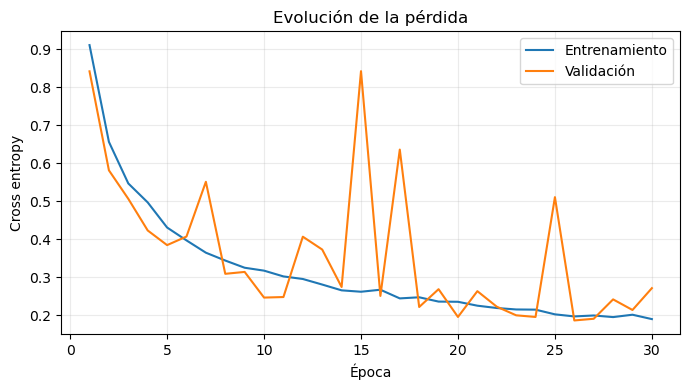

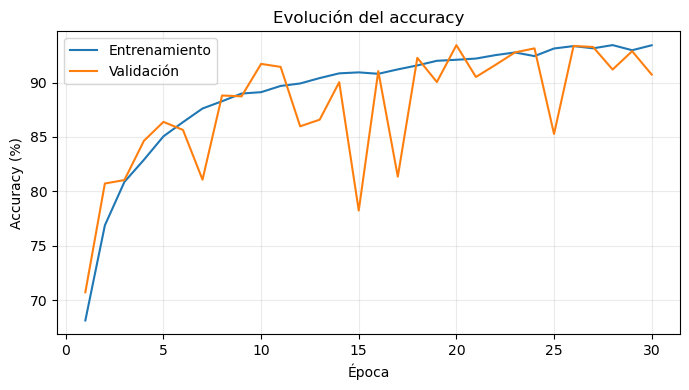

In [ ]:

epochs = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_loss'], label='Entrenamiento')
plt.plot(epochs, history['val_loss'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Cross entropy')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_acc'], label='Entrenamiento')
plt.plot(epochs, history['val_acc'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Accuracy (%)')
plt.title('Evolución del accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


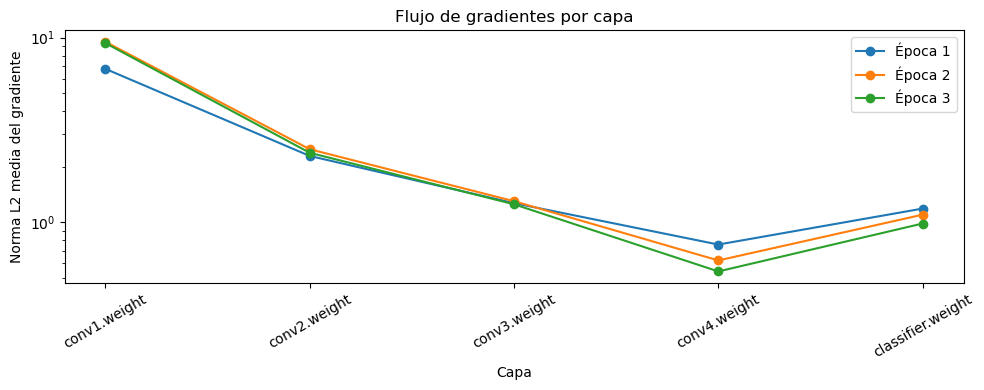

In [ ]:
plt.figure(figsize=(10, 4))
for record in gradient_history:
    names = list(record['capas'])
    normas = []
    for name in names:
        normas.append(np.mean(record['capas'][name]))
    plt.plot(names, normas, marker='o', label='Época ' + str(record['epoch']))
plt.yscale('log')
plt.xlabel('Capa')
plt.ylabel('Norma L2 media del gradiente')
plt.title('Flujo de gradientes por capa')
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


### Resultados de la CNN
La CNN tiene 98.970 parámetros entrenables. En 30 épocas, la pérdida de entrenamiento
bajó de 0,9109 a 0,1898 y el accuracy subió de 68,13 % a 93,43 %.
La menor pérdida de validación fue 0,1863 en la época 26, con 93,37 % de accuracy.
En la última época, el accuracy de validación fue 90,74 %.

Durante las primeras tres épocas, las normas medias de los gradientes fueron finitas
y se mantuvieron en rangos similares para cada capa entre épocas.
En ese tramo no se observan señales claras de desvanecimiento o explosión.


## 2. Análisis de errores y espacio latente
### Evaluación en test
Evaluamos la CNN con los pesos seleccionados por validación. Reportamos accuracy
y precision, recall y F1 por clase.

In [ ]:
cnn_custom = model  
history_custom = copy.deepcopy(history)
best_epoch_custom = best_epoch
best_val_acc_custom = best_val_acc

def predecir(modelo, loader):
    modelo.eval()
    reales = []
    predichas = []
    with torch.no_grad():  
        for images, labels in loader:
            images = images.to(device)
            logits = modelo(images)
            _, predicted = torch.max(logits, 1)
            reales.extend(labels.tolist())
            predichas.extend(predicted.cpu().tolist())
    return np.array(reales), np.array(predichas)

y_test, pred_custom = predecir(cnn_custom, test_loader)
acc_custom = accuracy_score(y_test, pred_custom)
print('Accuracy test:', round(acc_custom, 4))

def mostrar_metricas(reales, predichas):
    reporte = classification_report(reales, predichas, labels=range(num_classes),
                                    target_names=class_names, zero_division=0, output_dict=True)
    tabla_metricas = '| Clase | Precision | Recall | F1 | Imágenes |\n'
    tabla_metricas += '|---|---:|---:|---:|---:|\n'
    for name in class_names:
        fila = reporte[name]
        tabla_metricas += (f'| {name} | {fila["precision"]:.2f} | {fila["recall"]:.2f} | '
                           f'{fila["f1-score"]:.2f} | {int(fila["support"])} |\n')
    display(Markdown(tabla_metricas))

mostrar_metricas(y_test, pred_custom)


Accuracy test: 0.947


| Clase | Precision | Recall | F1 | Imágenes |
|---|---:|---:|---:|---:|
| AnnualCrop | 0.97 | 0.92 | 0.95 | 300 |
| Forest | 0.99 | 0.97 | 0.98 | 300 |
| HerbaceousVegetation | 0.96 | 0.86 | 0.90 | 300 |
| Highway | 0.95 | 0.93 | 0.94 | 250 |
| Industrial | 0.98 | 0.96 | 0.97 | 250 |
| Pasture | 0.88 | 0.95 | 0.92 | 200 |
| PermanentCrop | 0.87 | 0.96 | 0.91 | 250 |
| Residential | 0.97 | 1.00 | 0.98 | 300 |
| River | 0.90 | 0.94 | 0.92 | 250 |
| SeaLake | 0.98 | 0.99 | 0.98 | 300 |


### Matriz de confusión

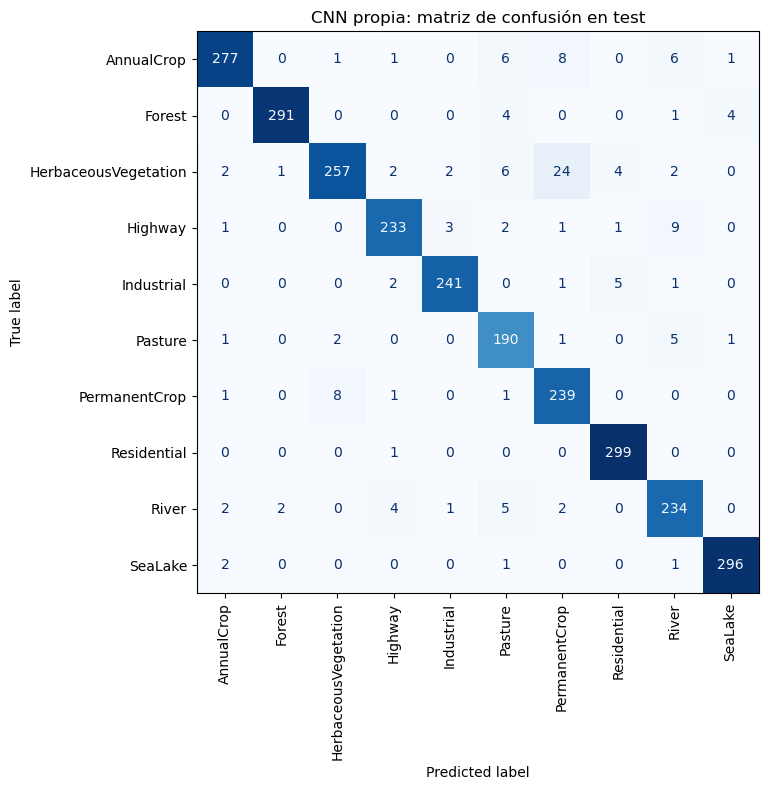

In [ ]:
cm_custom = confusion_matrix(y_test, pred_custom, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_custom, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90
)
ax.set_title('CNN propia: matriz de confusión en test')
plt.tight_layout()
plt.show()


### Confusiones más frecuentes

In [ ]:
# Agrupamos ambos sentidos de cada confusión.
pares = []
for a in range(num_classes):
    for b in range(a + 1, num_classes):
        cantidad = int(cm_custom[a, b] + cm_custom[b, a])
        if cantidad > 0:
            pares.append((cantidad, a, b))
pares.sort(reverse=True)
tabla_pares = '| Clase A | Clase B | Total | A → B | B → A |\n'
tabla_pares += '|---|---|---:|---:|---:|\n'
for cantidad, a, b in pares[:5]:
    tabla_pares += (f'| {class_names[a]} | {class_names[b]} | {cantidad} | '
                    f'{cm_custom[a, b]} | {cm_custom[b, a]} |\n')
display(Markdown(tabla_pares))


| Clase A | Clase B | Total | A → B | B → A |
|---|---|---:|---:|---:|
| HerbaceousVegetation | PermanentCrop | 32 | 24 | 8 |
| Highway | River | 13 | 9 | 4 |
| Pasture | River | 10 | 5 | 5 |
| AnnualCrop | PermanentCrop | 9 | 8 | 1 |
| HerbaceousVegetation | Pasture | 8 | 6 | 2 |


### Análisis de errores
La CNN confundió 24 imágenes de HerbaceousVegetation con PermanentCrop y 8 en el sentido inverso.
En los recortes revisados se ven manchas de vegetación y suelo en la primera clase,
y superficies verdes o hileras poco definidas en la segunda. A 64 × 64, el patrón de
las hileras puede ser difícil de distinguir.

Hubo 9 imágenes de Highway clasificadas como River y 4 en el sentido inverso.
Dos ejemplos de Highway muestran trazos angostos sobre fondos oscuros o verdes.
La forma alargada es un rasgo visual que carreteras y ríos pueden compartir.


### Espacio latente
Extraemos las 128 características previas al clasificador de la CNN. Ajustamos PCA con
entrenamiento y proyectamos test. Para t-SNE usamos una muestra de 2.000 imágenes de test
y las etiquetas solo para colorear los puntos.


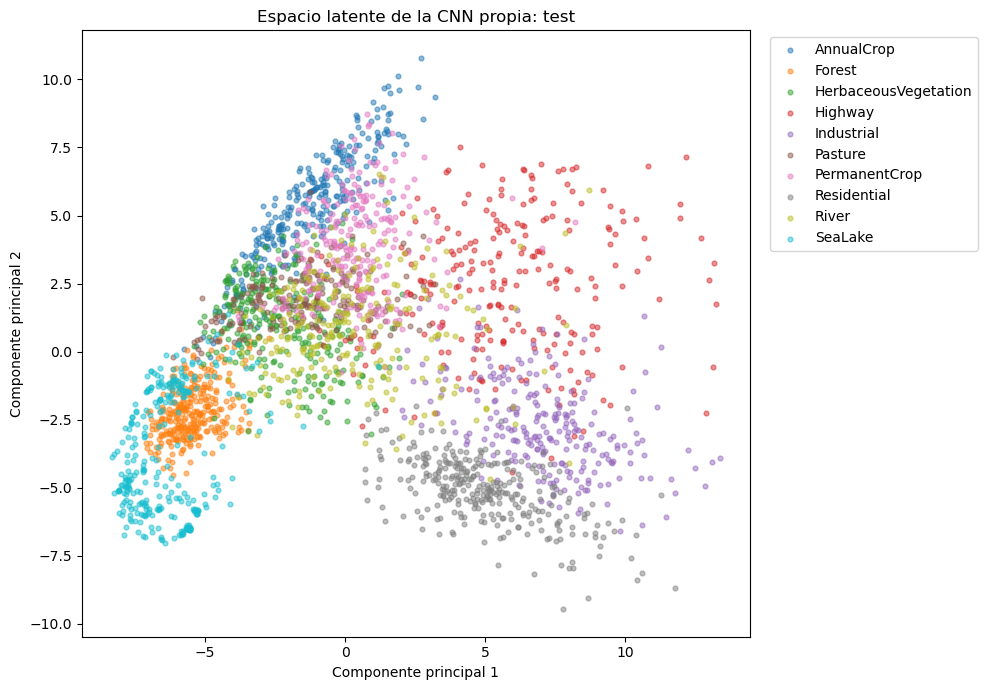

Las dos componentes conservan 45.7% de la varianza de las características de entrenamiento. Para interpretar los grupos debemos considerar esa pérdida de información.

In [ ]:
def extraer_features(modelo, loader):
    modelo.eval()
    features = []
    etiquetas = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            salida = modelo.forward_features(images)  # Antes del clasificador.
            features.append(salida.cpu().numpy())
            etiquetas.extend(labels.tolist())
    return np.concatenate(features, axis=0), np.array(etiquetas)

train_latente_dataset = Subset(eval_full, train_indices)
train_latente_loader = DataLoader(train_latente_dataset, batch_size=BATCH_SIZE,
                                  shuffle=False, num_workers=NUM_WORKERS)
features_train, labels_latentes_train = extraer_features(cnn_custom, train_latente_loader)
features_test, labels_latentes_test = extraer_features(cnn_custom, test_loader)

pca = PCA(n_components=2, svd_solver='full')
pca.fit(features_train)  # Sin utilizar test para ajustar la proyección.
proyeccion_test = pca.transform(features_test)
varianza_pca = pca.explained_variance_ratio_.sum()

plt.figure(figsize=(10, 7))
for label in range(num_classes):
    seleccion = labels_latentes_test == label
    plt.scatter(proyeccion_test[seleccion, 0], proyeccion_test[seleccion, 1],
                s=12, alpha=0.5, label=class_names[label])
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Espacio latente de la CNN propia: test')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
display(Markdown(f'Las dos componentes conservan {varianza_pca:.1%} de la '
                 'varianza de las características de entrenamiento. '
                 'Para interpretar los grupos debemos considerar esa pérdida de información.'))


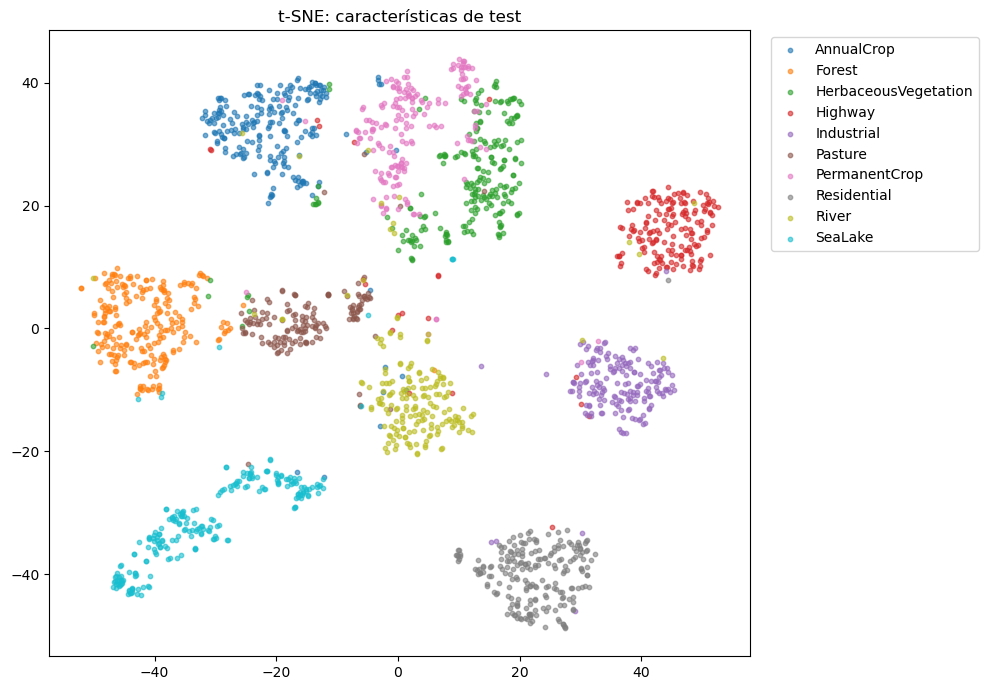

In [ ]:
from sklearn.manifold import TSNE
muestreo = np.random.default_rng(SEED)
indices_latentes = muestreo.choice(len(features_test), min(2000, len(features_test)), replace=False)
features_muestra = features_test[indices_latentes]
labels_muestra = labels_latentes_test[indices_latentes]
tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED)
proyeccion_tsne = tsne.fit_transform(features_muestra)
plt.figure(figsize=(10, 7))
for label in range(num_classes):
    seleccion = labels_muestra == label
    plt.scatter(proyeccion_tsne[seleccion, 0], proyeccion_tsne[seleccion, 1],
                s=10, alpha=0.6, label=class_names[label])
plt.title('t-SNE: características de test')
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


### Análisis del espacio latente
En la corrida guardada en el historial, las dos componentes de PCA conservaron el 45,7 %
de la varianza de entrenamiento. Forest y SeaLake se concentran hacia la izquierda,
mientras que HerbaceousVegetation, PermanentCrop y Pasture se superponen en la zona central.

En t-SNE, Residential, Industrial y Highway forman grupos bien diferenciados.
HerbaceousVegetation y PermanentCrop se mezclan en algunas zonas, en línea con la
confusión más frecuente de la CNN.


## 3. Transfer learning
Cargamos ResNet18 con pesos de ImageNet y reemplazamos su clasificador por una capa
de 10 salidas. Ajustamos `layer4` con una tasa de 0,0001 y `fc` con 0,001.


In [ ]:
EPOCHS_TL = EPOCHS
LR_TL = 1e-3
train_loader_tl = train_loader
val_loader_tl = val_loader
test_loader_tl = test_loader


In [ ]:
torch.manual_seed(SEED)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_tl = models.resnet18(weights=weights)
for parameter in model_tl.parameters():
    parameter.requires_grad = False  
for parameter in model_tl.layer4.parameters():
    parameter.requires_grad = True  
model_tl.fc = nn.Linear(model_tl.fc.in_features, num_classes)
model_tl = model_tl.to(device)
optimizer_tl = torch.optim.Adam([
    {'params': model_tl.layer4.parameters(), 'lr': 1e-4},
    {'params': model_tl.fc.parameters(), 'lr': 1e-3},
])
print('Entrenables:', sum(p.numel() for p in model_tl.parameters() if p.requires_grad))


Entrenables: 8398858


### Fine-tuning
Durante el entrenamiento dejamos las capas congeladas en modo evaluación para conservar
sus estadísticas de BatchNorm. Seleccionamos el estado con menor pérdida de validación.


In [ ]:
def entrenar_una_epoca_tl(modelo, loader, criterion, optimizer):
    modelo.eval()  
    modelo.layer4.train()
    modelo.fc.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = modelo(images)  
        loss = criterion(logits, labels)
        loss.backward()  
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total

history_tl = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'seconds': []}
best_val_loss_tl = float('inf')
best_epoch_tl = 0
best_val_acc_tl = 0.0
for epoch in range(1, EPOCHS_TL + 1):
    inicio = time.time()
    train_loss, train_acc = entrenar_una_epoca_tl(model_tl, train_loader_tl, criterion, optimizer_tl)
    val_loss, val_acc = evaluar(model_tl, val_loader_tl, criterion)
    seconds = time.time() - inicio
    for key, value in [('train_loss', train_loss), ('val_loss', val_loss),
                       ('train_acc', train_acc), ('val_acc', val_acc), ('seconds', seconds)]:
        history_tl[key].append(value)
    print(f'ResNet18 {epoch}/{EPOCHS_TL} | train {train_loss:.4f}, {train_acc:.2f}% '
          f'| val {val_loss:.4f}, {val_acc:.2f}% | {seconds:.1f} s', flush=True)
    if val_loss < best_val_loss_tl:
        best_val_loss_tl, best_val_acc_tl, best_epoch_tl = val_loss, val_acc, epoch
        best_tl_weights = copy.deepcopy(model_tl.state_dict())
model_tl.load_state_dict(best_tl_weights)
model_tl.eval()
print('Mejor época ResNet18:', best_epoch_tl)


ResNet18 1/30 | train 0.3666, 87.96% | val 0.1939, 93.70% | 144.5 s


KeyboardInterrupt: 

### Velocidad de convergencia y tiempo
Comparamos pérdida y accuracy de validación por época. Ambos modelos usan los
mismos CSV, lotes de 64, imágenes de 64 × 64 y 30 épocas.
La tabla final incluye el tiempo medio por época de la corrida registrada,
que contempla lectura de datos, entrenamiento y validación.


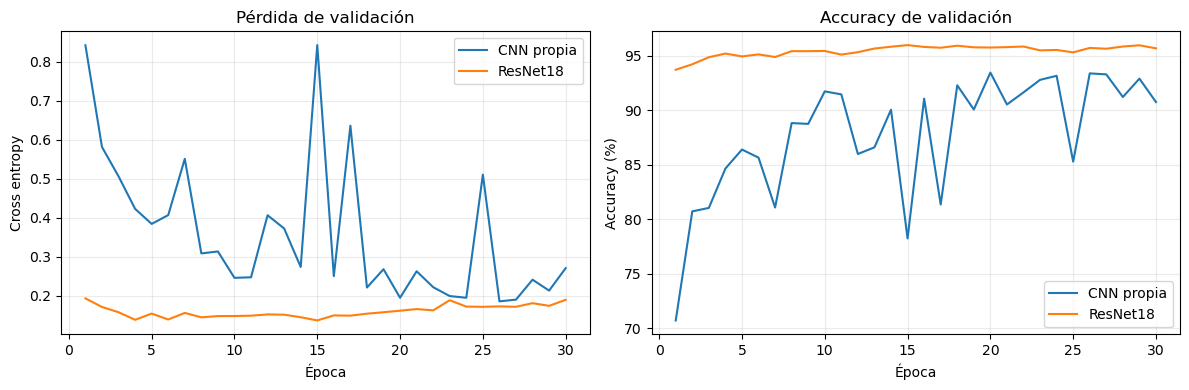

| Época | Accuracy val CNN (%) | Accuracy val ResNet18 (%) |
|---:|---:|---:|
| 1 | 70.72 | 93.70 |
| 2 | 80.72 | 94.20 |
| 3 | 81.04 | 94.85 |
| 4 | 84.65 | 95.19 |
| 5 | 86.39 | 94.93 |
| 6 | 85.65 | 95.11 |
| 7 | 81.07 | 94.87 |
| 8 | 88.81 | 95.41 |
| 9 | 88.74 | 95.41 |
| 10 | 91.72 | 95.43 |
| 11 | 91.44 | 95.09 |
| 12 | 85.98 | 95.31 |
| 13 | 86.59 | 95.65 |
| 14 | 90.04 | 95.81 |
| 15 | 78.24 | 95.96 |
| 16 | 91.06 | 95.80 |
| 17 | 81.35 | 95.72 |
| 18 | 92.28 | 95.91 |
| 19 | 90.06 | 95.76 |
| 20 | 93.44 | 95.74 |
| 21 | 90.52 | 95.78 |
| 22 | 91.63 | 95.83 |
| 23 | 92.78 | 95.48 |
| 24 | 93.15 | 95.52 |
| 25 | 85.28 | 95.30 |
| 26 | 93.37 | 95.70 |
| 27 | 93.28 | 95.63 |
| 28 | 91.20 | 95.83 |
| 29 | 92.89 | 95.94 |
| 30 | 90.74 | 95.67 |


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, historial in [('CNN propia', history_custom), ('ResNet18', history_tl)]:
    epochs_modelo = range(1, len(historial['val_loss']) + 1)
    axes[0].plot(epochs_modelo, historial['val_loss'], label=name)
    axes[1].plot(epochs_modelo, historial['val_acc'], label=name)
axes[0].set_title('Pérdida de validación')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Cross entropy')
axes[1].set_title('Accuracy de validación')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy (%)')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


tabla_epocas = '| Época | Accuracy val CNN (%) | Accuracy val ResNet18 (%) |\n'
tabla_epocas += '|---:|---:|---:|\n'
epocas_comunes = min(len(history_custom['val_acc']), len(history_tl['val_acc']))
for epoch in range(epocas_comunes):
    tabla_epocas += (f'| {epoch + 1} | {history_custom["val_acc"][epoch]:.2f} | '
                     f'{history_tl["val_acc"][epoch]:.2f} |\n')
display(Markdown(tabla_epocas))


### Rendimiento final en test
Los modelos se evalúan con los pesos elegidos por validación. Presentamos las
métricas por clase y una tabla que compara accuracy y tiempo medio por época.

| Clase | Precision | Recall | F1 | Imágenes |
|---|---:|---:|---:|---:|
| AnnualCrop | 0.95 | 0.97 | 0.96 | 300 |
| Forest | 0.98 | 0.99 | 0.99 | 300 |
| HerbaceousVegetation | 0.96 | 0.95 | 0.96 | 300 |
| Highway | 0.94 | 0.89 | 0.91 | 250 |
| Industrial | 0.96 | 0.98 | 0.97 | 250 |
| Pasture | 0.94 | 0.96 | 0.95 | 200 |
| PermanentCrop | 0.95 | 0.93 | 0.94 | 250 |
| Residential | 0.99 | 0.99 | 0.99 | 300 |
| River | 0.93 | 0.96 | 0.94 | 250 |
| SeaLake | 1.00 | 0.99 | 1.00 | 300 |


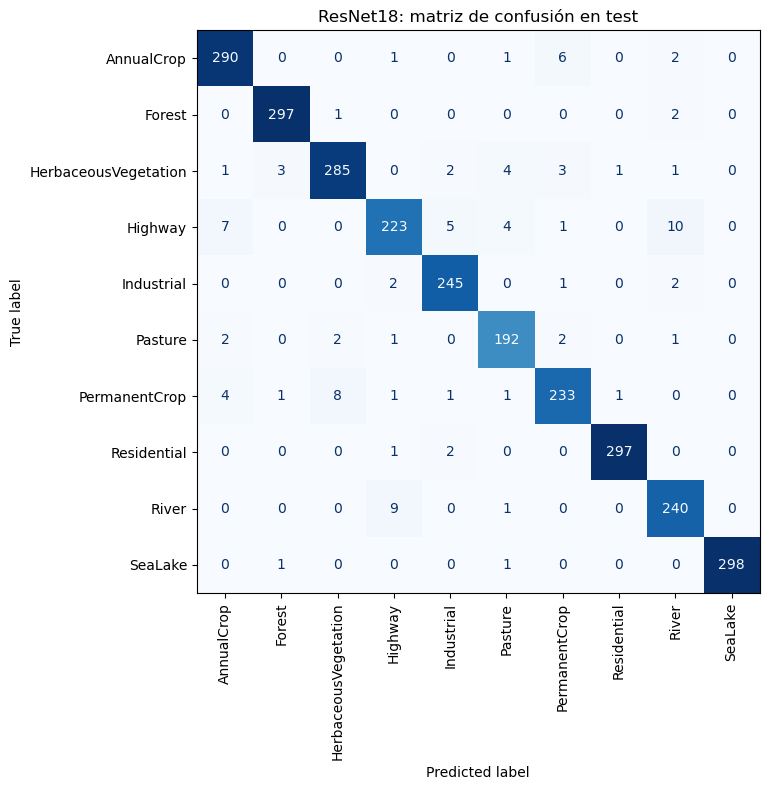

| Modelo | Accuracy test | Mejor época (val loss) | Val accuracy de esa época | Segundos/época |
|---|---:|---:|---:|---:|
| CNN propia | 0.9470 | 26 | 93.37% | 56.09 |
| ResNet18 | 0.9630 | 15 | 95.96% | 143.62 |


In [ ]:
y_test_tl, pred_tl = predecir(model_tl, test_loader_tl)
assert np.array_equal(y_test, y_test_tl)
acc_tl = accuracy_score(y_test_tl, pred_tl)
mostrar_metricas(y_test_tl, pred_tl)

cm_tl = confusion_matrix(y_test_tl, pred_tl, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_tl, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90
)
ax.set_title('ResNet18: matriz de confusión en test')
plt.tight_layout()
plt.show()

tiempo_custom = float(np.mean(history_custom['seconds']))
tiempo_tl = float(np.mean(history_tl['seconds']))
tabla = '| Modelo | Accuracy test | Mejor época (val loss) | Val accuracy de esa época | Segundos/época |\n'
tabla += '|---|---:|---:|---:|---:|\n'
tabla += (f'| CNN propia | {acc_custom:.4f} | {best_epoch_custom} | '
          f'{best_val_acc_custom:.2f}% | {tiempo_custom:.2f} |\n')
tabla += (f'| ResNet18 | {acc_tl:.4f} | {best_epoch_tl} | '
          f'{best_val_acc_tl:.2f}% | {tiempo_tl:.2f} |\n')
display(Markdown(tabla))


## Conclusión

La CNN propia obtuvo 94,70 % de accuracy en test. En entrenamiento, la pérdida
bajó de 0,9109 a 0,1898, aunque el rendimiento en validación osciló bastante.
La época 26 tuvo la menor pérdida de validación (0,1863) y un accuracy de 93,37 %.
En la última época, el accuracy de validación cayó a 90,74 %. Esa diferencia
muestra por qué convino recuperar los pesos de la época 26.

ResNet18 obtuvo 96,30 % en test, 1,6 puntos porcentuales más que la CNN.
La ventaja apareció temprano. En la primera época ya tenía 93,70 % de accuracy
en validación, por encima del máximo de la CNN en las 30 épocas (93,44 %).
Su menor pérdida de validación fue 0,1374 en la época 15, con un accuracy de
95,96 %. El accuracy de entrenamiento siguió subiendo hasta 99,14 %, mientras
que la pérdida de validación terminó en 0,1902. Las últimas épocas mejoraron
el ajuste sobre entrenamiento, pero el mejor estado en validación ya se había
alcanzado antes.

La mejora en test fue desigual según la clase. El recall de HerbaceousVegetation
subió de 0,86 a 0,95 y sus confusiones con PermanentCrop bajaron de 32 a 11
entre ambos sentidos. En Highway ocurrió lo contrario. Su recall bajó de 0,93
a 0,89 y las confusiones con River aumentaron de 13 a 19. El accuracy global
favorece a ResNet18, aunque la CNN reconoció mejor las imágenes de Highway.

### CNN desde cero y transfer learning

Tomando el 90 % de accuracy en validación como referencia, la CNN entrenada
desde cero superó ese nivel en la décima época. ResNet18 lo superó en la primera.
Eso muestra que el modelo preentrenado llegó a un buen resultado con menos
épocas de ajuste. En la comparación de las 30 épocas, la CNN tuvo un tiempo medio
de 56,09 s por época, frente a 143,62 s de ResNet18.

Con la CNN obtuvimos 94,70 % en test usando 98.970 parámetros entrenables.
El ajuste de ResNet18 involucró 8.398.858 parámetros y alcanzó 96,30 %.
La diferencia de 1,6 puntos porcentuales vino acompañada de menos confusiones
entre las dos clases de vegetación más problemáticas para la CNN. Para Highway,
la CNN mantuvo el mejor recall. En esta corrida, la CNN fue la opción más
liviana y ResNet18 dio el mejor resultado global. Como también cambió la
arquitectura, la comparación mide el resultado de los dos enfoques completos.
